# OpenCV 08 — Morphological Operations

Binary-image operations based on a **structuring element**. Morphology is mainly used to remove noise, connect regions, fill gaps, and refine segmentation masks.

## 1. Structuring Element
A structuring element (kernel) defines the neighborhood used to inspect each pixel.

**Syntax:** `cv2.getStructuringElement(shape, ksize[, anchor])`

Shapes: `MORPH_RECT`, `MORPH_ELLIPSE`, `MORPH_CROSS`.

In [2]:
import cv2
import numpy as np

rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
print('RECT\n', rect)
print('ELLIPSE\n', ellipse)
print('CROSS\n', cross)

RECT
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
ELLIPSE
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
CROSS
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


## 2. Erosion
Erosion **shrinks foreground objects** by removing boundary pixels. It is useful for removing small foreground noise.

For a binary image, a pixel remains foreground only when the structuring element fits completely inside the foreground.

### Mathematical View

For binary sets, erosion is:

$$
A \ominus B = \{x \mid B_x \subseteq A\}
$$

So the output contains positions where the shifted structuring element `B` is completely contained in the foreground set `A`.

In [3]:
img = np.zeros((200, 300), dtype=np.uint8)
cv2.rectangle(img, (70, 50), (230, 150), 255, -1)

kernel = np.ones((7, 7), np.uint8)
eroded = cv2.erode(img, kernel, iterations=1)
print(img.shape, eroded.shape)

(200, 300) (200, 300)


**Parameters:** `cv2.erode(src, kernel, dst=None, anchor=(-1,-1), iterations=1, borderType=...)`

`iterations` repeats the erosion; larger kernels or more iterations cause stronger shrinking.

## 3. Dilation
Dilation **expands foreground objects** by adding pixels around their boundaries. It can close small gaps and reconnect nearby components.

A binary pixel becomes foreground when the structuring element overlaps the foreground.

### Mathematical View

$$
A \oplus B = \{x \mid (B_x \cap A) \neq \emptyset\}
$$

Unlike erosion, only one foreground overlap is enough to activate the output position.

In [4]:
dilated = cv2.dilate(img, kernel, iterations=1)

**Syntax:** `cv2.dilate(src, kernel[, dst[, anchor[, iterations[, borderType]]]])`

## 4. Erosion vs Dilation

| Operation | Main effect | Typical use |
|---|---|---|
| Erosion | Shrinks foreground | Remove small white noise |
| Dilation | Expands foreground | Fill small gaps / connect regions |

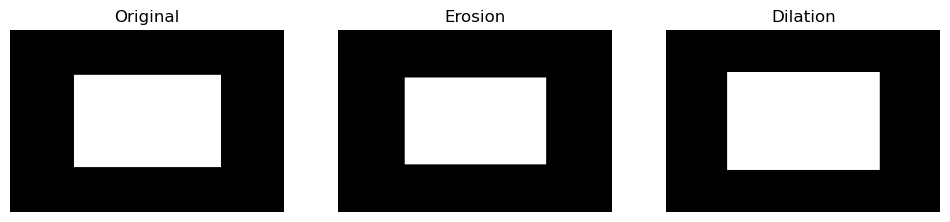

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, title in zip(ax, [img, eroded, dilated], ['Original', 'Erosion', 'Dilation']):
    a.imshow(im, cmap='gray'); a.set_title(title); a.axis('off')
plt.show()

## 5. Opening
**Opening = erosion → dilation.** It removes small foreground objects/noise while preserving the general shape of larger objects.

### Formula

$$
A \circ B = (A \ominus B) \oplus B
$$

In [6]:
opened = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel, iterations=1)

**Syntax:** `cv2.morphologyEx(src, op, kernel[, dst[, anchor[, iterations[, borderType[, borderValue]]]]])`

Use `MORPH_OPEN` for isolated white noise in a binary mask.

## 6. Closing
**Closing = dilation → erosion.** It fills small holes and closes small gaps inside or between foreground regions.

### Formula

$$
A \bullet B = (A \oplus B) \ominus B
$$

In [7]:
closed = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel, iterations=1)

Use `MORPH_CLOSE` when the foreground object is mostly correct but contains small black holes or breaks.

## 7. Opening vs Closing

**Opening:** removes small white regions.

**Closing:** removes small black regions inside/around foreground.

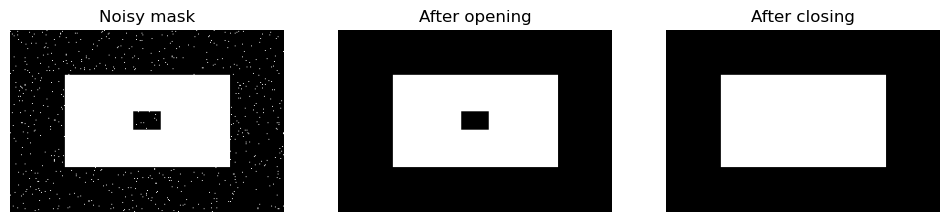

In [16]:
# Example with white noise and a black hole
mask = np.zeros((200, 300), np.uint8)
cv2.rectangle(mask, (60, 50), (240, 150), 255, -1)
mask[90:110, 135:165] = 0
noise = np.random.default_rng(0).random(mask.shape) < 0.015
mask[noise] = 255

opened_mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5), np.uint8))
closed_mask = cv2.morphologyEx(opened_mask, cv2.MORPH_CLOSE, np.ones((31,31), np.uint8))

fig, ax = plt.subplots(1,3,figsize=(12,4))
for a,im,t in zip(ax,[mask,opened_mask,closed_mask],['Noisy mask','After opening','After closing']):
    a.imshow(im,cmap='gray'); a.set_title(t); a.axis('off')
plt.show()

## 8. Morphological Gradient
The morphological gradient is **dilation − erosion**. It produces a boundary-like outline of foreground objects.

\[G = (A \oplus B) - (A \ominus B)\]

In [9]:
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)

## 9. Top Hat

Top hat extracts small bright objects/details from a brighter background.

$$
T = A - (A \circ B)
$$

In [10]:
tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

## 10. Black Hat
Black hat extracts small dark objects/details from a brighter foreground/background structure.

\[B = (A ullet B) - A\]

In [11]:
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

## 11. Hit-or-Miss
Hit-or-miss detects a specific binary pattern using foreground and background conditions.

**Syntax:** `cv2.morphologyEx(src, cv2.MORPH_HITMISS, kernel)`; primarily for binary `0/1` patterns.

In [12]:
binary = (img > 0).astype(np.uint8)
hitmiss_kernel = np.array([[-1,-1,-1],[-1,1,-1],[-1,-1,-1]], dtype=np.int8)
hitmiss = cv2.morphologyEx(binary, cv2.MORPH_HITMISS, hitmiss_kernel)
print('Unique values:', np.unique(hitmiss))

Unique values: [0]


## 12. Kernel Shape Matters
A rectangular kernel treats its neighborhood as a block; an ellipse gives smoother/rounder behavior; a cross emphasizes horizontal/vertical structure.

In [13]:
k_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (7,7))
k_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
k_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (7,7))

## 13. Iterations
`iterations=2` applies the same morphological operation twice. Increasing iterations generally makes erosion stronger and dilation larger.

In [14]:
erode_1 = cv2.erode(img, kernel, iterations=1)
erode_3 = cv2.erode(img, kernel, iterations=3)

## 14. Practical Segmentation Cleanup Pipeline
A common CV pipeline is:

**threshold/HSV mask → opening (remove noise) → closing (fill gaps) → contours**

In [15]:
# Generic mask-cleaning pipeline
mask = cv2.inRange(np.zeros((200,300,3), np.uint8), (0,0,0), (0,0,0))  # placeholder mask
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
clean = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, k)

## 15. Important Parameters

- `kernel`: neighborhood/structuring element.
- `iterations`: number of repetitions.
- `anchor`: kernel reference point; `(-1,-1)` means center.
- `borderType`: how pixels outside the image are handled.
- `borderValue`: constant used with constant borders.

## 16. Function Cheat Sheet

| Function | Purpose |
|---|---|
| `getStructuringElement()` | Create morphology kernel |
| `erode()` | Shrink foreground |
| `dilate()` | Expand foreground |
| `morphologyEx(..., MORPH_OPEN)` | Remove small bright noise |
| `morphologyEx(..., MORPH_CLOSE)` | Fill small dark gaps/holes |
| `MORPH_GRADIENT` | Extract boundaries |
| `MORPH_TOPHAT` | Extract small bright details |
| `MORPH_BLACKHAT` | Extract small dark details |
| `MORPH_HITMISS` | Detect binary patterns |